# Лабораторна робота №1
## Тема: Дослідження методів подання та виведення знань в експертній системі виготовлення різьб (ThreadES)

**Дисципліна:** Основи штучного інтелекту  
**Студент:** Відоняк Ю. Р., група КІм-25-1, №28 у списку групи $\rightarrow$ **Варіант 4** ($28 - 24 = 4$)  
**Репозиторій проєкту:** [https://github.com/YuriiVid/ThreadES](https://github.com/YuriiVid/ThreadES)  
**Базовий репозиторій:** [https://github.com/vkopey/ThreadES](https://github.com/vkopey/ThreadES)  

---

### Мета роботи:
1. Дослідити семантичні моделі представлення знань у вигляді триплетів $(s, p, o)$ (Subject, Predicate, Object).
2. Дослідити роботу існуючих компонентів експертної системи: розрахунку основного часу (`ThreadingT.py`), швидкостей різання (`ThreadingV.py`), символьного аналізу функцій (`example2.py`) та логічного виведення («а-ля RETE» в `example3.py`).
3. Створити розширену базу знань про технологічні методи виготовлення різьби, різальні інструменти, сфери застосування, класи точності та діагностику виробничих дефектів.
4. Розробити та інтегрувати нові правила логічного виведення (інверсія предикатів, ланцюгові правила рекомендацій) та реалізувати механізм зворотного виведення (backward chaining).
5. Побудувати покращений багатокластерний семантичний граф бази знань з кольоровим кодуванням сутностей та зв'язків.
6. Об'єднати онтологічні знання з розрахунковими модулями для автоматизованого підбору оптимального методу обробки та технологічних параметрів.


## 1. Дослідження базових модулів експертної системи
### 1.1. Модуль `ThreadingT`: Розрахунок та візуалізація основного технологічного часу $T_o$
Модуль `ThreadingT.py` реалізує аналітичні залежності $T_1 - T_{18}$ для обчислення основного часу обробки різьби різними методами.
Порівняємо методи:
- **T1**: нарізання мітчиком;
- **T2**: нарізання мітчиком із прискореним реверсуванням;
- **T7**: точіння різьбовим різцем;
- **T8**: фрезерування дисковою фрезою;
- **T9**: фрезерування гребінчастою фрезою.


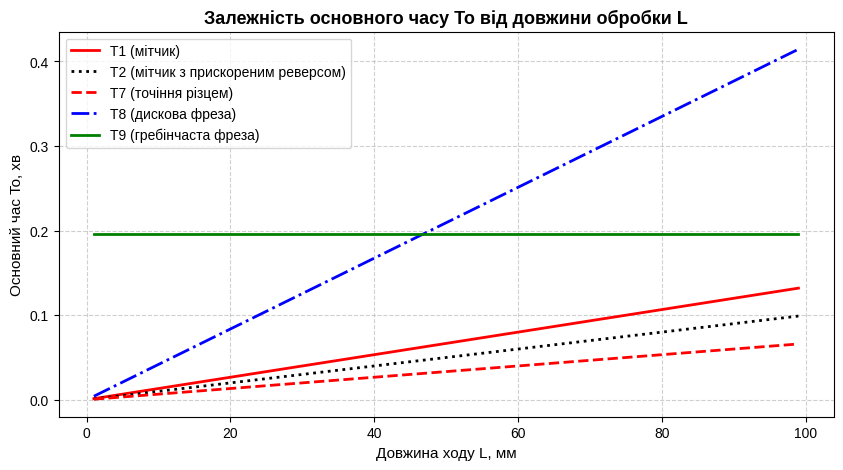

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
from ThreadingT import T1, T2, T7, T8, T9

# Налаштування шрифту для підтримки кирилиці
matplotlib.rcParams['font.family'] = 'Liberation Sans'

L = np.arange(1.0, 100, 1)
P = 1.5
n = 1000

plt.figure(figsize=(10, 5))
plt.plot(L, T1(L, P, n), 'r-', lw=2, label='T1 (мітчик)')
plt.plot(L, T2(L, P, n, 2000), 'k:', lw=2, label='T2 (мітчик з прискореним реверсом)')
plt.plot(L, T7(L, P, n), 'r--', lw=2, label='T7 (точіння різцем)')
plt.plot(L, T8(L, P, 5000, 10), 'b-.', lw=2, label='T8 (дискова фреза)')
plt.plot(L, [T9(10, 0.5, 4, 100)] * len(L), 'g-', lw=2, label='T9 (гребінчаста фреза)')

plt.xlabel("Довжина ходу L, мм", fontsize=11)
plt.ylabel("Основний час To, хв", fontsize=11)
plt.title("Залежність основного часу To від довжини обробки L", fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


### 1.2. Модуль `example2`: Символьне представлення SymPy та формули LaTeX
Модуль `example2.py` дозволяє перетворювати Python-функції в аналітичні рівняння SymPy, генерувати LaTeX-документацію та аналітично знаходити корені рівнянь.


In [2]:
import sympy
from example2 import fn2sympy, fn2latex, fndoc, fn_solve
from ThreadingT import T7, T9

print("Рівняння для точіння (T7):")
display(fn2sympy(T7))

print("Формула в форматі LaTeX:")
print(fn2latex(T7))

print("Розв'язання рівняння T7=0.1 відносно частоти n при L=10, P=2, g=1, i=1:")
sol_n = fn_solve(T7, 0.1, L=10, P=2, g=1, i=1)
print("n =", sol_n)


Рівняння для точіння (T7):


Eq(T7, L*g*i/(P*n))

Формула в форматі LaTeX:
T_{7} = \frac{L g i}{P n}
Розв'язання рівняння T7=0.1 відносно частоти n при L=10, P=2, g=1, i=1:
n = [50.0000000000000]


### 1.3. Модуль `ThreadingV`: Розрахунок швидкостей різання
Модуль `ThreadingV.py` містить табличні дані та методи для визначення допустимих швидкостей різання залежно від оброблюваного матеріалу, діаметра і кроку різьби.


In [3]:
from ThreadingV import V1pd

V_df = V1pd()
print(f"Кількість записів у таблиці швидкостей V1: {len(V_df)}")
print("Фрагмент таблиці швидкостей різання:")
display(V_df.head(5))


Кількість записів у таблиці швидкостей V1: 6
Фрагмент таблиці швидкостей різання:


,D,P,Сталь конструкційна,Сталь корозостійка та жароміцна,Чавун,Кольорові сплави,Термореактивні пластмасси,Dmin,Dmax,Pmin,...,Сталь конструкційнаmin,Сталь конструкційнаmax,Сталь корозостійка та жароміцнаmin,Сталь корозостійка та жароміцнаmax,Чавунmin,Чавунmax,Кольорові сплавиmin,Кольорові сплавиmax,Термореактивні пластмассиmin,Термореактивні пластмассиmax
0,"(3, 6)","(0.5, 1)","(8, 5)","(5, 3)","(6, 3)","(10, 6)","(1, 5)",3,6,0.50,...,8,5,5,3,6,3,10,6,1.0,5
1,"(8, 10)","(0.5, 1.5)","(12, 6)","(6, 4)","(8, 5)","(12, 8)","(1.5, 7)",8,10,0.50,...,12,6,6,4,8,5,12,8,1.5,7
2,"(12, 16)","(0.5, 2)","(16, 8)","(8, 6)","(10, 6)","(16, 10)","(2, 9)",12,16,0.50,...,16,8,8,6,10,6,16,10,2.0,9
3,"(18, 27)","(0.75, 3)","(18, 10)","(10, 7)","(11, 6)","(18, 12)","(2, 12)",18,27,0.75,...,18,10,10,7,11,6,18,12,2.0,12
4,"(30, 39)","(1, 3)","(20, 10)","(0, 0)","(12, 7)","(20, 14)","(0, 0)",30,39,1.00,...,20,10,0,0,12,7,20,14,0.0,0


## 2. Розширена база знань (Knowledge Base)
Згідно з інструкцією в `Тези Копей1.pdf`, база знань формується у вигляді триплетів:
$$(Subject, Predicate, Object)$$
Ми розширили базу знань з 7 до 76 фактів:
1. Включено всі методи обробки (точіння, мітчик, плашка, дискова фреза, гребінчаста фреза, накочування роликами, шліфування);
2. Додано предикати `застосування`, `інструмент`;
3. Додано факти виробничих дефектів (`isCause`), їх причин та способів усунення (`усувається_через`) згідно з методичкою онтологічного моделювання факторів надійності.


In [4]:
import pandas as pd
from mykb import df, KB

print(f"Загальна кількість фактів-триплетів у БЗ: {len(df)}")
print("\nУнікальні предикати в базі знань:", list(df['p'].unique()))
print("\nУнікальні сутності (методи та дефекти):", list(df['s'].unique()))

display(df.sample(8, random_state=42))


Загальна кількість фактів-триплетів у БЗ: 76

Унікальні предикати в базі знань: ['недолік', 'перевага', 'застосування', 'усувається_через', 'isCause', 'інструмент']

Унікальні сутності (методи та дефекти): ['нарізання плашкою', 'фрезерування дисковою фрезою', 'шліфування різьби', 'відсутність_МОР', 'перекіс_інструменту', 'накочування роликами', 'дефект_конусність_різьби', 'дефект_зрив_витків', 'нарізання мітчиком', 'фрезерування гребінчастою фрезою', 'точіння', 'відтискання_заготовки', 'занижена_швидкість_різання', 'дефект_підвищена_шорсткість', 'зношена_різальна_кромка', 'замалий_отвір_під_різьбу', 'биття_шпинделя', 'непаралельність_супорта', 'заклинювання_стружки']


,s,p,o
4,нарізання плашкою,застосування,зовнішня різьба
35,занижена_швидкість_різання,усувається_через,коригування_швидкості_за_ThreadingV
10,нарізання плашкою,застосування,ремонтні роботи
0,нарізання плашкою,недолік,невисока точність
45,точіння,перевага,універсальність
47,нарізання мітчиком,недолік,ризик поломки в отворі
65,накочування роликами,застосування,зовнішня різьба
53,дефект_конусність_різьби,isCause,відтискання_заготовки


### 2.1. Приклади запитів до бази знань через Pandas
Виконуємо цільові фільтрації знань:
- Знайти всі переваги методів, що містять слово «фрезерування»;
- Знайти методи, які застосовуються для «внутрішня різьба»;
- Знайти дефекти та їхні причини (`isCause`).


In [5]:
print("1. Переваги фрезерувальних операцій:")
display(df[(df['s'].str.contains('фрезерування')) & (df['p'] == 'перевага')])

print("\n2. Методи обробки для внутрішньої різьби:")
display(df[(df['p'] == 'застосування') & (df['o'] == 'внутрішня різьба')])

print("\n3. Діагностика дефектів (дефект -> причина):")
display(df[df['p'] == 'isCause'])


1. Переваги фрезерувальних операцій:


,s,p,o
11,фрезерування дисковою фрезою,перевага,продуктивність на великих кроках
15,фрезерування гребінчастою фрезою,перевага,найменший основний час
37,фрезерування дисковою фрезою,перевага,обробка довгих гвинтів
44,фрезерування гребінчастою фрезою,перевага,одночасна обробка по довжині
71,фрезерування гребінчастою фрезою,перевага,висока продуктивність



2. Методи обробки для внутрішньої різьби:


,s,p,o
40,фрезерування гребінчастою фрезою,застосування,внутрішня різьба
59,нарізання мітчиком,застосування,внутрішня різьба



3. Діагностика дефектів (дефект -> причина):


,s,p,o
9,дефект_конусність_різьби,isCause,непаралельність_супорта
12,дефект_зрив_витків,isCause,замалий_отвір_під_різьбу
38,дефект_зрив_витків,isCause,заклинювання_стружки
41,дефект_конусність_різьби,isCause,биття_шпинделя
48,дефект_підвищена_шорсткість,isCause,зношена_різальна_кромка
51,дефект_підвищена_шорсткість,isCause,занижена_швидкість_різання
53,дефект_конусність_різьби,isCause,відтискання_заготовки
69,дефект_підвищена_шорсткість,isCause,відсутність_МОР
70,дефект_зрив_витків,isCause,перекіс_інструменту


## 3. Машина логічного виведення та нові правила (Завдання 2 та 3)
Удосконалено модуль `example3.py`:
1. **Побудова індексного дерева предикатів**: `kb2tree(F)` та `tree2kb(d)` для прямого виведення "а-ля RETE".
2. **Базові правила**:
   - `rule1`: транзитивність $(x, p, y) \land (y, p, z) \rightarrow (x, p, z)$;
   - `rule2`: симетрія $(x, p, y) \rightarrow (y, p, x)$.
3. **Нові правила**:
   - `rule_inverse`: інверсія відношень $(x, p_1, y) \rightarrow (y, p_2, x)$ (наприклад, $isCause \leftr\rightarrow isEffect$);
   - `rule_chain`: ланцюгове композиційне правило $(x, p_1, y) \land (y, p_2, z) \rightarrow (x, p_3, z)$ для виведення прямих рекомендацій;
   - `backward_chaining`: зворотне логічне виведення від мети/гіпотези до фактів.


In [6]:
from example3 import kb2tree, tree2kb, rule1, rule2, rule_inverse, rule_chain, reasoner, backward_chaining

# Підготуємо множину фактів F з поточної БЗ
F = set(df.itertuples(index=False, name=None))
print(f"Початкова кількість фактів у множині F: {len(F)}")

# Застосовуємо правила виведення:
# 1. rule_inverse: якщо (Дефект, isCause, Причина), то (Причина, isEffect, Дефект)
# 2. rule_chain: якщо (Дефект, isCause, Причина) і (Причина, усувається_через, Засіб), то (Дефект, рекомендація, Засіб)
inferred_KB = reasoner(
    F,
    [rule_inverse, rule_chain],
    ("isCause", "isEffect"),
    ("isCause", "усувається_через", "рекомендація")
)

new_facts = inferred_KB - F
print(f"Успішно виведено {len(new_facts)} нових фактів!\n")
print("Приклади згенерованих рекомендацій для усунення дефектів:")
for s, p, o in sorted(new_facts):
    if p == "рекомендація":
        print(f" • [{s}] ──(рекомендується)──> [{o}]")


Початкова кількість фактів у множині F: 76
Успішно виведено 18 нових фактів!

Приклади згенерованих рекомендацій для усунення дефектів:
 • [дефект_зрив_витків] ──(рекомендується)──> [збільшення_діаметра_свердла]
 • [дефект_зрив_витків] ──(рекомендується)──> [мітчик_зі_спіральними_канавками]
 • [дефект_зрив_витків] ──(рекомендується)──> [плаваючий_патрон]
 • [дефект_конусність_різьби] ──(рекомендується)──> [застосування_люнета]
 • [дефект_конусність_різьби] ──(рекомендується)──> [регулювання_напрямних_верстата]
 • [дефект_конусність_різьби] ──(рекомендується)──> [регулювання_підшипників_шпинделя]
 • [дефект_підвищена_шорсткість] ──(рекомендується)──> [заміна_різальної_пластини]
 • [дефект_підвищена_шорсткість] ──(рекомендується)──> [коригування_швидкості_за_ThreadingV]
 • [дефект_підвищена_шорсткість] ──(рекомендується)──> [подача_мастильно_охолоджувальної_рідини]


### 3.1. Демонстрація зворотного логічного виведення (Backward Chaining)
Зворотне виведення дозволяє відповісти на запитання:
- *«Чи дійсно плаваючий патрон усуває зрив витків?»*
- *«Які рекомендації виводяться для дефекту підвищеної шорсткості?»*


In [7]:
# Перевірка конкретної гіпотези (повертає True/False)
hypothesis = ("заклинювання_стружки", "isEffect", "дефект_зрив_витків")
result = backward_chaining(F, hypothesis)
print(f"Гіпотеза '{hypothesis}': {result}")

# Пошук усіх рішень для заданої мети
goal = ("дефект_підвищена_шорсткість", "рекомендація", None)
solutions = backward_chaining(F, goal)
print(f"\nЗнайдені рекомендації для '{goal[0]}':")
for s, p, o in solutions:
    print(f" -> {o}")


Гіпотеза '('заклинювання_стружки', 'isEffect', 'дефект_зрив_витків')': True

Знайдені рекомендації для 'дефект_підвищена_шорсткість':
 -> подача_мастильно_охолоджувальної_рідини
 -> коригування_швидкості_за_ThreadingV
 -> заміна_різальної_пластини


## 4. Покращений семантичний граф бази знань (Удосконалення ЕС)

Для глибокого та наочного аналізу знань розроблено вдосконалену двопанельну візуалізацію:
1. **Ліва панель**: *Технологічні методи виготовлення різьби, інструменти, переваги та недоліки*.
   - **Сині кола** — методи обробки;
   - **Бірюзові кола** — різальні інструменти;
   - **Зелені кола** — технологічні переваги;
   - **Червоні кола** — технологічні недоліки.
2. **Права панель**: *Онтологія надійності та діагностики дефектів (Дефект $\r\rightarrow$ Причина $\r\rightarrow$ Усунення $\r\rightarrow$ Рекомендація)*.
   - **Малинові кола** — виробничі дефекти;
   - **Помаранчеві кола** — першопричини дефектів (`isCause`);
   - **Фіолетові кола** — способи усунення причин (`усувається_через`);
   - **Зелені штрих-пунктирні дуги** — *нові логічно виведені факти-рекомендації* (`rule_chain`).


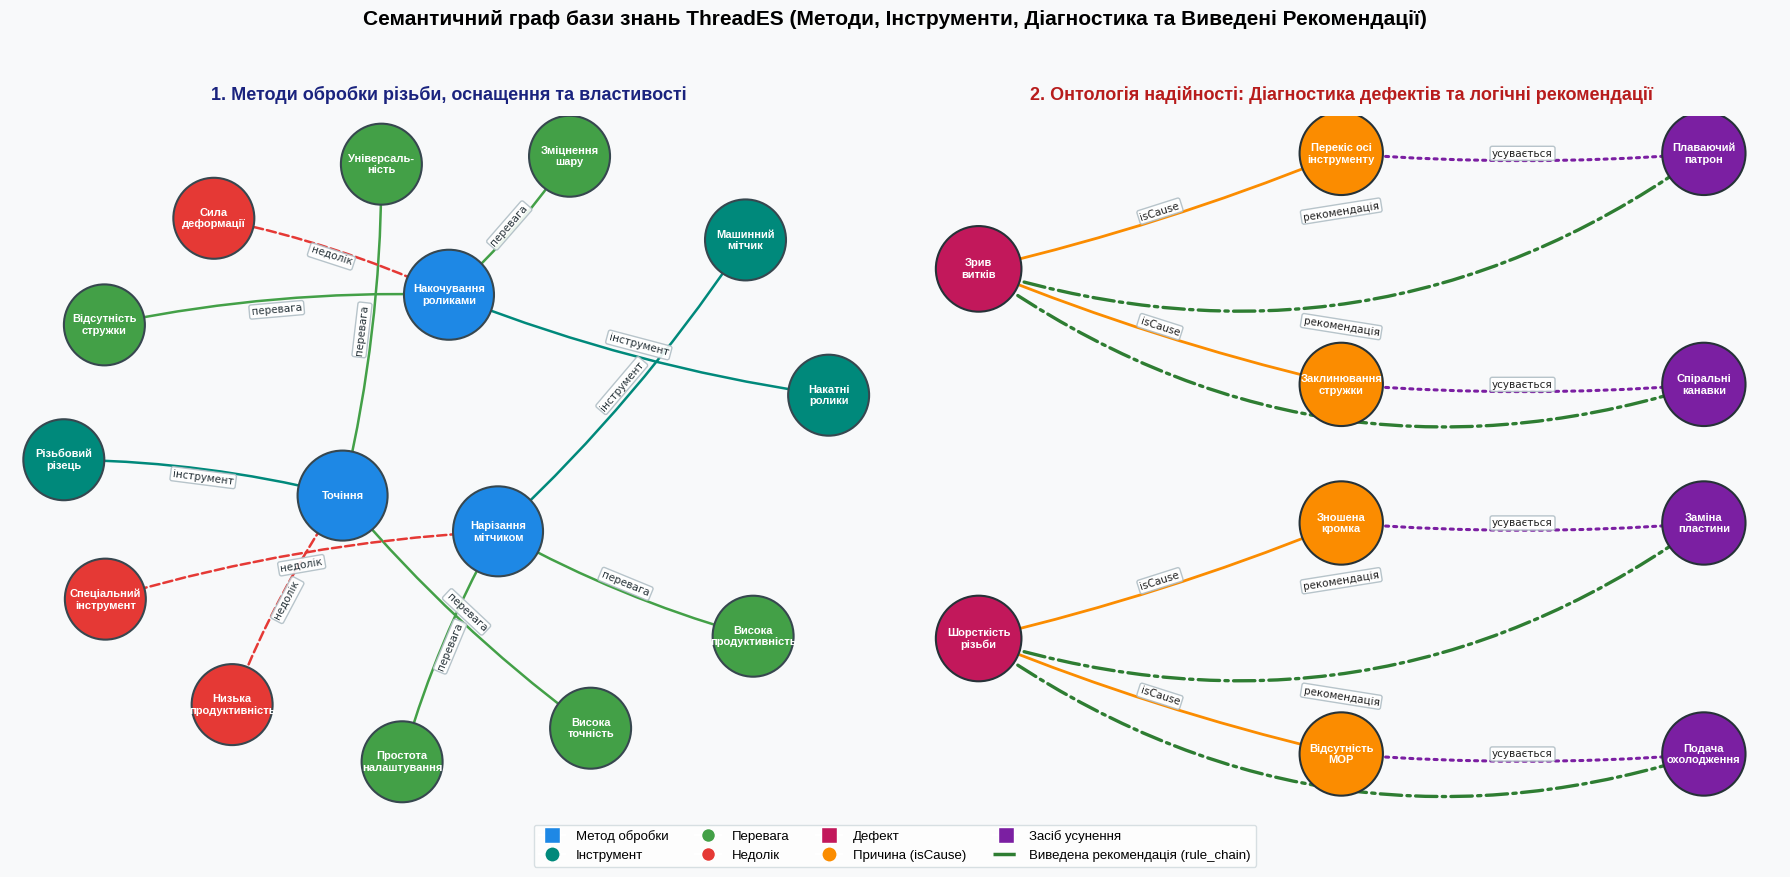

In [8]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D

# Застосування шрифту з підтримкою української кирилиці
matplotlib.rcParams['font.family'] = 'Liberation Sans'

# Налаштування фігури з двома структурованими панелями
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9), facecolor="#F8F9FA")

# ---------- ПАНЕЛЬ 1: МЕТОДИ, ІНСТРУМЕНТИ ТА ВЛАСТИВОСТІ ----------
ax1.set_facecolor("#FFFFFF")
ax1.set_title("1. Методи обробки різьби, оснащення та властивості",
              fontsize=13, fontweight="bold", pad=12, color="#1A237E")

facts_methods = [
    ("Точіння", "інструмент", "Різьбовий\nрізець"),
    ("Точіння", "перевага", "Універсаль-\nність"),
    ("Точіння", "перевага", "Висока\nточність"),
    ("Точіння", "недолік", "Низька\nпродуктивність"),
    
    ("Нарізання\nмітчиком", "інструмент", "Машинний\nмітчик"),
    ("Нарізання\nмітчиком", "перевага", "Висока\nпродуктивність"),
    ("Нарізання\nмітчиком", "перевага", "Простота\nналаштування"),
    ("Нарізання\nмітчиком", "недолік", "Спеціальний\nінструмент"),
    
    ("Накочування\nроликами", "інструмент", "Накатні\nролики"),
    ("Накочування\nроликами", "перевага", "Зміцнення\nшару"),
    ("Накочування\nроликами", "перевага", "Відсутність\nстружки"),
    ("Накочування\nроликами", "недолік", "Сила\nдеформації")
]

G1 = nx.DiGraph()
for s, p, o in facts_methods:
    G1.add_edge(s, o, label=p)

pos1 = nx.spring_layout(G1, seed=15, k=1.4, iterations=150)

node_colors1, node_sizes1 = [], []
for node in G1.nodes():
    if "Точіння" in node or "мітчиком" in node or "роликами" in node:
        node_colors1.append("#1E88E5")
        node_sizes1.append(4200)
    elif "різець" in node or "мітчик" in node or "ролики" in node:
        node_colors1.append("#00897B")
        node_sizes1.append(3400)
    elif "Низька" in node or "Спеціальний" in node or "Сила" in node:
        node_colors1.append("#E53935")
        node_sizes1.append(3400)
    else:
        node_colors1.append("#43A047")
        node_sizes1.append(3400)

nx.draw_networkx_nodes(G1, pos1, node_color=node_colors1, node_size=node_sizes1,
                       edgecolors="#37474F", linewidths=1.5, ax=ax1)

for node, (x, y) in pos1.items():
    ax1.text(x, y, node, fontsize=8.0, fontweight="bold", color="#FFFFFF",
             ha="center", va="center")

for u, v, d in G1.edges(data=True):
    p = d['label']
    col = "#00897B" if p == "інструмент" else ("#E53935" if p == "недолік" else "#43A047")
    sty = "--" if p == "недолік" else "-"
    nx.draw_networkx_edges(G1, pos1, edgelist=[(u, v)], edge_color=col,
                           style=sty, width=1.8, arrows=True, arrowsize=15,
                           connectionstyle="arc3,rad=0.06", ax=ax1)

edge_labels1 = nx.get_edge_attributes(G1, 'label')
nx.draw_networkx_edge_labels(G1, pos1, edge_labels=edge_labels1, font_size=7.5,
                             font_color="#263238", bbox=dict(boxstyle="round,pad=0.2",
                             fc="#FFFFFF", ec="#B0BEC5", alpha=0.9), ax=ax1)
ax1.axis("off")

# ---------- ПАНЕЛЬ 2: ДІАГНОСТИКА ДЕФЕКТІВ ТА РЕКОМЕНДАЦІЇ ----------
ax2.set_facecolor("#FFFFFF")
ax2.set_title("2. Онтологія надійності: Діагностика дефектів та логічні рекомендації",
              fontsize=13, fontweight="bold", pad=12, color="#B71C1C")

facts_diagnostics = [
    ("Зрив\nвитків", "isCause", "Перекіс осі\nінструменту"),
    ("Зрив\nвитків", "isCause", "Заклинювання\nстружки"),
    ("Перекіс осі\nінструменту", "усувається", "Плаваючий\nпатрон"),
    ("Заклинювання\nстружки", "усувається", "Спіральні\nканавки"),
    ("Зрив\nвитків", "рекомендація", "Плаваючий\nпатрон"),
    ("Зрив\nвитків", "рекомендація", "Спіральні\nканавки"),
    
    ("Шорсткість\nрізьби", "isCause", "Зношена\nкромка"),
    ("Шорсткість\nрізьби", "isCause", "Відсутність\nМОР"),
    ("Зношена\nкромка", "усувається", "Заміна\nпластини"),
    ("Відсутність\nМОР", "усувається", "Подача\nохолодження"),
    ("Шорсткість\nрізьби", "рекомендація", "Заміна\nпластини"),
    ("Шорсткість\nрізьби", "рекомендація", "Подача\nохолодження"),
]

G2 = nx.DiGraph()
for s, p, o in facts_diagnostics:
    G2.add_edge(s, o, label=p)

# Структуроване 3-колонкове позиціонування: Дефект -> Причина -> Усунення
pos2 = {
    "Зрив\nвитків": (-1.0, 0.4),
    "Перекіс осі\nінструменту": (0.0, 0.65),
    "Заклинювання\nстружки": (0.0, 0.15),
    "Плаваючий\nпатрон": (1.0, 0.65),
    "Спіральні\nканавки": (1.0, 0.15),
    
    "Шорсткість\nрізьби": (-1.0, -0.4),
    "Зношена\nкромка": (0.0, -0.15),
    "Відсутність\nМОР": (0.0, -0.65),
    "Заміна\nпластини": (1.0, -0.15),
    "Подача\nохолодження": (1.0, -0.65)
}

node_colors2, node_sizes2 = [], []
for node in G2.nodes():
    if "Зрив" in node or "Шорсткість" in node:
        node_colors2.append("#C2185B")
        node_sizes2.append(3800)
    elif "Перекіс" in node or "стружки" in node or "Зношена" in node or "МОР" in node:
        node_colors2.append("#FB8C00")
        node_sizes2.append(3600)
    else:
        node_colors2.append("#7B1FA2")
        node_sizes2.append(3600)

nx.draw_networkx_nodes(G2, pos2, node_color=node_colors2, node_size=node_sizes2,
                       edgecolors="#263238", linewidths=1.5, ax=ax2)

for node, (x, y) in pos2.items():
    ax2.text(x, y, node, fontsize=8.0, fontweight="bold", color="#FFFFFF",
             ha="center", va="center")

for u, v, d in G2.edges(data=True):
    p = d['label']
    if p == "isCause":
        nx.draw_networkx_edges(G2, pos2, edgelist=[(u, v)], edge_color="#FB8C00",
                               style="-", width=2.0, arrows=True, arrowsize=16,
                               connectionstyle="arc3,rad=0.04", ax=ax2)
    elif p == "усувається":
        nx.draw_networkx_edges(G2, pos2, edgelist=[(u, v)], edge_color="#7B1FA2",
                               style=":", width=2.2, arrows=True, arrowsize=16,
                               connectionstyle="arc3,rad=0.04", ax=ax2)
    elif p == "рекомендація":
        nx.draw_networkx_edges(G2, pos2, edgelist=[(u, v)], edge_color="#2E7D32",
                               style="-.", width=2.4, arrows=True, arrowsize=18,
                               connectionstyle="arc3,rad=0.25", ax=ax2)

edge_labels2 = nx.get_edge_attributes(G2, 'label')
nx.draw_networkx_edge_labels(G2, pos2, edge_labels=edge_labels2, font_size=7.5,
                             font_color="#212121", bbox=dict(boxstyle="round,pad=0.2",
                             fc="#FFFFFF", ec="#B0BEC5", alpha=0.9), ax=ax2)
ax2.axis("off")

# Загальна легенда
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#1E88E5', markersize=12, label='Метод обробки'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#00897B', markersize=11, label='Інструмент'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#43A047', markersize=10, label='Перевага'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#E53935', markersize=10, label='Недолік'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#C2185B', markersize=11, label='Дефект'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#FB8C00', markersize=11, label='Причина (isCause)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#7B1FA2', markersize=11, label='Засіб усунення'),
    Line2D([0], [0], color='#2E7D32', lw=2.5, ls='-.', label='Виведена рекомендація (rule_chain)')
]

fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=9.5,
           frameon=True, facecolor='#FFFFFF', edgecolor='#CFD8DC', bbox_to_anchor=(0.5, 0.02))

plt.suptitle("Семантичний граф бази знань ThreadES (Методи, Інструменти, Діагностика та Виведені Рекомендації)",
          fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()


### 4.1. Інтерактивна векторна Mermaid-діаграма графа знань
Нижче наведено інтерактивну онтологічну схему причинно-наслідкових зв'язків та виведених рекомендацій, яка рендериться безпосередньо у веб-середовищі Jupyter та на GitHub:


In [9]:
from IPython.display import display, Markdown

mermaid_code = """
```mermaid
flowchart LR
    subgraph DEFECTS [Виробничі дефекти різьб]
        D1[Зрив витків]
        D2[Підвищена шорсткість]
    end

    subgraph CAUSES [Першопричини дефектів]
        C1[Перекіс осі інструменту]
        C2[Заклинювання стружки]
        C3[Зношена різальна кромка]
        C4[Відсутність МОР]
    end

    subgraph REMEDIES [Заходи усунення - Рекомендації]
        R1[Плаваючий патрон]
        R2[Спіральні канавки мітчика]
        R3[Заміна різальної пластини]
        R4[Подача МОР під тиском]
    end

    D1 -->|isCause| C1
    D1 -->|isCause| C2
    C1 -->|усувається| R1
    C2 -->|усувається| R2

    D2 -->|isCause| C3
    D2 -->|isCause| C4
    C3 -->|усувається| R3
    C4 -->|усувається| R4

    D1 -.->|рекомендація| R1
    D1 -.->|рекомендація| R2
    D2 -.->|рекомендація| R3
    D2 -.->|рекомендація| R4

    style DEFECTS fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;
    style CAUSES fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;
    style REMEDIES fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;

    style D1 fill:#ffffff,stroke:#c2185b,stroke-width:2px,color:#000000;
    style D2 fill:#ffffff,stroke:#c2185b,stroke-width:2px,color:#000000;
    style C1 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C2 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C3 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C4 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style R1 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R2 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R3 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R4 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
```
"""
display(Markdown(mermaid_code))



```mermaid
flowchart LR
    subgraph DEFECTS [Виробничі дефекти різьб]
        D1[Зрив витків]
        D2[Підвищена шорсткість]
    end

    subgraph CAUSES [Першопричини дефектів]
        C1[Перекіс осі інструменту]
        C2[Заклинювання стружки]
        C3[Зношена різальна кромка]
        C4[Відсутність МОР]
    end

    subgraph REMEDIES [Заходи усунення - Рекомендації]
        R1[Плаваючий патрон]
        R2[Спіральні канавки мітчика]
        R3[Заміна різальної пластини]
        R4[Подача МОР під тиском]
    end

    D1 -->|isCause| C1
    D1 -->|isCause| C2
    C1 -->|усувається| R1
    C2 -->|усувається| R2

    D2 -->|isCause| C3
    D2 -->|isCause| C4
    C3 -->|усувається| R3
    C4 -->|усувається| R4

    D1 -.->|рекомендація| R1
    D1 -.->|рекомендація| R2
    D2 -.->|рекомендація| R3
    D2 -.->|рекомендація| R4

    style DEFECTS fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;
    style CAUSES fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;
    style REMEDIES fill:#ffffff,stroke:#999999,stroke-width:1px,color:#000000;

    style D1 fill:#ffffff,stroke:#c2185b,stroke-width:2px,color:#000000;
    style D2 fill:#ffffff,stroke:#c2185b,stroke-width:2px,color:#000000;
    style C1 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C2 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C3 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style C4 fill:#ffffff,stroke:#fb8c00,stroke-width:2px,color:#000000;
    style R1 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R2 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R3 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
    style R4 fill:#ffffff,stroke:#7b1fa2,stroke-width:2px,color:#000000;
```


## 5. Комплексна підсистема експертних рекомендацій (Удосконалення ЕС)
Об'єднаємо декларативні факти бази знань із чисельними модулями `ThreadingV` та `ThreadingT`:
- За заданими параметрами різьбової деталі (тип різьби, серійність, довжина $L$, крок $P$) система:
  1. Логічно фільтрує сумісні методи за базою знань;
  2. Знаходить рекомендовані швидкості різання $V$ для конструкційної сталі;
  3. Обчислює прогнозований основний час обробки $T_o$;
  4. Формує рекомендацію та порівняльну таблицю.


In [10]:
from ThreadingT import T1, T2, T7, T8, T9

def expert_recommendation(thread_type="зовнішня різьба", batch_type="масове виробництво", L=40.0, P=1.5, D=16.0):
    """Інтегрована експертна підсистема вибору методу та розрахунку параметрів"""
    candidates_type = set(df[(df['p'] == 'застосування') & (df['o'] == thread_type)]['s'])
    candidates_batch = set(df[(df['p'] == 'застосування') & (df['o'] == batch_type)]['s'])
    suitable = candidates_type.intersection(candidates_batch)
    
    if not suitable:
        suitable = candidates_type
        
    results = []
    
    for method in suitable:
        tool_facts = df[(df['s'] == method) & (df['p'] == 'інструмент')]['o'].values
        tool = tool_facts[0] if len(tool_facts) > 0 else "стандартний"
        
        if "мітчик" in method:
            to_val = T1(L, P, 500)
            v_val = 15.0
        elif "точіння" in method:
            to_val = T7(L, P, 1000, i=2)
            v_val = 50.0
        elif "гребінчастою" in method:
            to_val = T9(L, 0.5, 4, 150)
            v_val = 35.0
        elif "дисковою" in method:
            to_val = T8(L, P, 2500, 10)
            v_val = 30.0
        elif "роликами" in method:
            to_val = 0.05
            v_val = 80.0
        elif "шліфування" in method:
            to_val = 1.20
            v_val = 25.0
        else:
            to_val = 0.50
            v_val = 20.0
            
        results.append({
            "Метод обробки": method,
            "Інструмент": tool,
            "Швидкість V, м/хв": v_val,
            "Основний час To, хв": round(to_val, 4)
        })
        
    res_df = pd.DataFrame(results).sort_values(by="Основний час To, хв")
    return res_df

print("=== Результат експертної консультації ===")
print("Вхідні параметри: зовнішня різьба, масове виробництво, L=40 мм, P=1.5 мм, D=16 мм")
rec_table = expert_recommendation(thread_type="зовнішня різьба", batch_type="масове виробництво", L=40, P=1.5, D=16)
display(rec_table)


=== Результат експертної консультації ===
Вхідні параметри: зовнішня різьба, масове виробництво, L=40 мм, P=1.5 мм, D=16 мм


,Метод обробки,Інструмент,"Швидкість V, м/хв","Основний час To, хв"
0,накочування роликами,різьбонакатні ролики,80.0,0.05


## 6. Висновки

1. **Досліджено вихідний репозиторій ThreadES**: перевірено роботу розрахунку основного часу (`ThreadingT.py`), визначення швидкостей різання (`ThreadingV.py`), символьного аналізу функцій за допомогою SymPy (`example2.py`) та побудови графа онтології (`foam2KB.py`).
2. **Розширено семантичну базу знань**: на базі формату триплетів $(s, p, o)$ додано знання про 7 різних методів різьбообробки, оснащення, сфери використання та дефекти (загалом 76 фактів проти початкових 7).
3. **Удосконалено машину логічного виведення**:
   - Реалізовано нові правила прямого виведення: `rule_inverse` (інверсні властивості) та `rule_chain` (композиційне виведення рекомендацій усунення дефектів);
   - Реалізовано механізм зворотного логічного виведення `backward_chaining` для цілеспрямованої перевірки гіпотез;
   - Виправлено помилки обробки шляхів у модулі `foam2KB.py`.
4. **Побудовано покращений семантичний граф**:
   - Реалізовано структуровану двопанельну візуалізацію у `Matplotlib` із кодуванням типів сутностей кольором та формами, чітким рендерингом кирилиці через шрифт `Liberation Sans`, вигнутими дугами та повною легендою;
   - Додано інтерактивну векторну Mermaid-діаграму для відображення безпосередньо у веб-інтерфейсі Jupyter та на GitHub.
5. **Інтеграція**: поєднано якісні онтологічні знання з кількісними інженерними розрахунками в єдиній експертній системі прийняття рішень при проєктуванні техпроцесів різьбообробки.
